# Phase 2: Modeling and Experimental Evaluation

## LitScope-Lite
Evidence-Based Verification of Scientific Claims Using NLP

### Research objective

Investigate a computationally practical pipeline for retrieving
scientific evidence, extracting relevant sentences and classifying
their relationship to scientific claims.

### Pipeline architecture

1. Rule-based scientific claim segmentation.
2. Hybrid TF-IDF and MiniLM document retrieval.
3. Semantic evidence sentence selection.
4. Two-tier DeBERTa natural language inference.
5. Claim-level aggregation and potential cross-source disagreement.

### Evaluation protocol

The experiments use the AllenAI SciFact development split and
its corpus of 5,183 scientific abstracts.

The pretrained models are used without task-specific fine-tuning.
Consequently, these experiments investigate zero-shot performance.

All results are loaded from saved experimental artifacts.
No model training or inference is performed by this notebook.

Development-set results should not be interpreted as independent
held-out test performance.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Image

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
)

ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

EVAL = ROOT / "outputs" / "evaluation"
IMG = ROOT / "images"

IMG.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 120

summary = json.loads(
    (EVAL / "phase2_evaluation_summary.json").read_text(
        encoding="utf-8"
    )
)

retrieval_df = pd.read_csv(
    EVAL / "retrieval_ablation_summary.csv"
)

rationale_df = pd.read_csv(
    EVAL / "rationale_selection_summary.csv"
)

stance_df = pd.read_csv(
    EVAL / "stance_oracle_predictions.csv"
)

routing_df = pd.read_csv(
    EVAL / "routing_threshold_sweep.csv"
)

old_e2e = pd.read_csv(
    EVAL / "end_to_end_threshold_060.csv"
)

new_e2e = pd.read_csv(
    EVAL / "end_to_end_sample_predictions.csv"
)

consistency_df = pd.read_csv(
    EVAL / "consistency_check.csv"
)

print("Evaluation artifacts loaded successfully.")
print("Oracle stance pairs:", len(stance_df))
print("Historical end-to-end claims:", len(old_e2e))
print("Updated end-to-end claims:", len(new_e2e))
print("Controlled consistency cases:", len(consistency_df))

def save_show(fig, filename):
    fig.tight_layout()
    fig.savefig(
        IMG / filename,
        dpi=220,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

Evaluation artifacts loaded successfully.
Oracle stance pairs: 338
Historical end-to-end claims: 60
Updated end-to-end claims: 60
Controlled consistency cases: 5


## 1. Document Retrieval Evaluation

TF-IDF captures lexical similarity, while MiniLM captures
semantic similarity between claims and scientific abstracts.

Three configurations are evaluated on the same 188
gold-annotated development claims:

- TF-IDF only: lexical weight 1.0.
- MiniLM only: semantic weight 1.0.
- Hybrid: equal lexical and semantic weights.

Metrics are macro-averaged across claims.

Recall measures the fraction of annotated relevant documents
retrieved. Hit rate measures whether at least one annotated
document was retrieved.

,method,k,num_claims,recall,precision,hit_rate,mrr
0,TF-IDF,1,188,0.6206,0.6436,0.6436,0.6436
1,TF-IDF,3,188,0.8036,0.2801,0.8191,0.7234
2,TF-IDF,5,188,0.8506,0.1798,0.8670,0.7338
3,TF-IDF,10,188,0.8998,0.0963,0.9096,0.7394
4,MiniLM,1,188,0.6055,0.6170,0.6170,0.6170
5,MiniLM,3,188,0.8043,0.2819,0.8245,0.7092
6,MiniLM,5,188,0.8685,0.1872,0.8777,0.7212
7,MiniLM,10,188,0.9117,0.1000,0.9202,0.7267
8,Hybrid,1,188,0.6844,0.7074,0.7074,0.7074
9,Hybrid,3,188,0.8326,0.2926,0.8511,0.7722


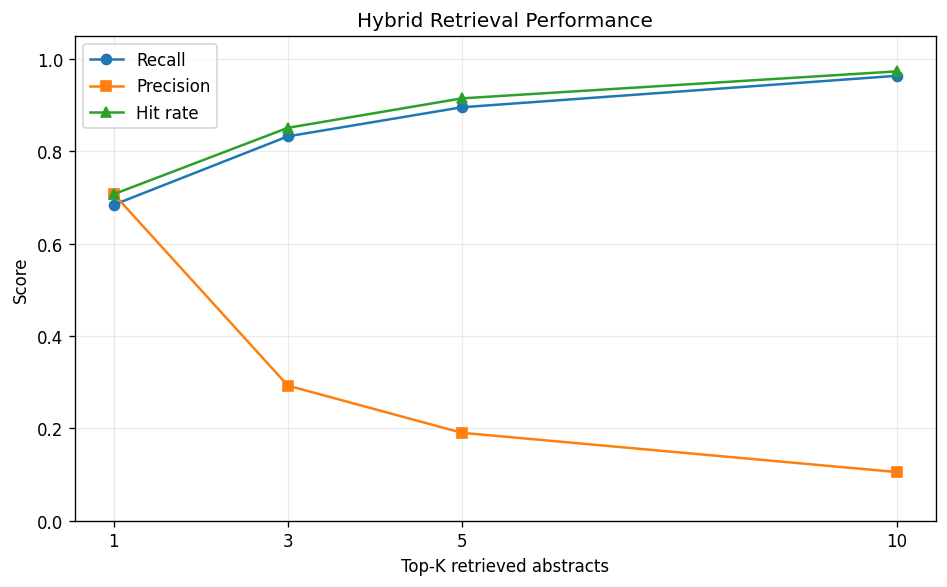

In [2]:
display(
    retrieval_df[
        [
            "method",
            "k",
            "num_claims",
            "recall",
            "precision",
            "hit_rate",
            "mrr",
        ]
    ]
)

hybrid = retrieval_df[
    retrieval_df["method"] == "Hybrid"
].sort_values("k")

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    hybrid["k"],
    hybrid["recall"],
    marker="o",
    label="Recall"
)

ax.plot(
    hybrid["k"],
    hybrid["precision"],
    marker="s",
    label="Precision"
)

ax.plot(
    hybrid["k"],
    hybrid["hit_rate"],
    marker="^",
    label="Hit rate"
)

ax.set_title("Hybrid Retrieval Performance")
ax.set_xlabel("Top-K retrieved abstracts")
ax.set_ylabel("Score")
ax.set_xticks(hybrid["k"])
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.25)
ax.legend()

save_show(
    fig,
    "04_01_retrieval_recall_precision_curve.png"
)

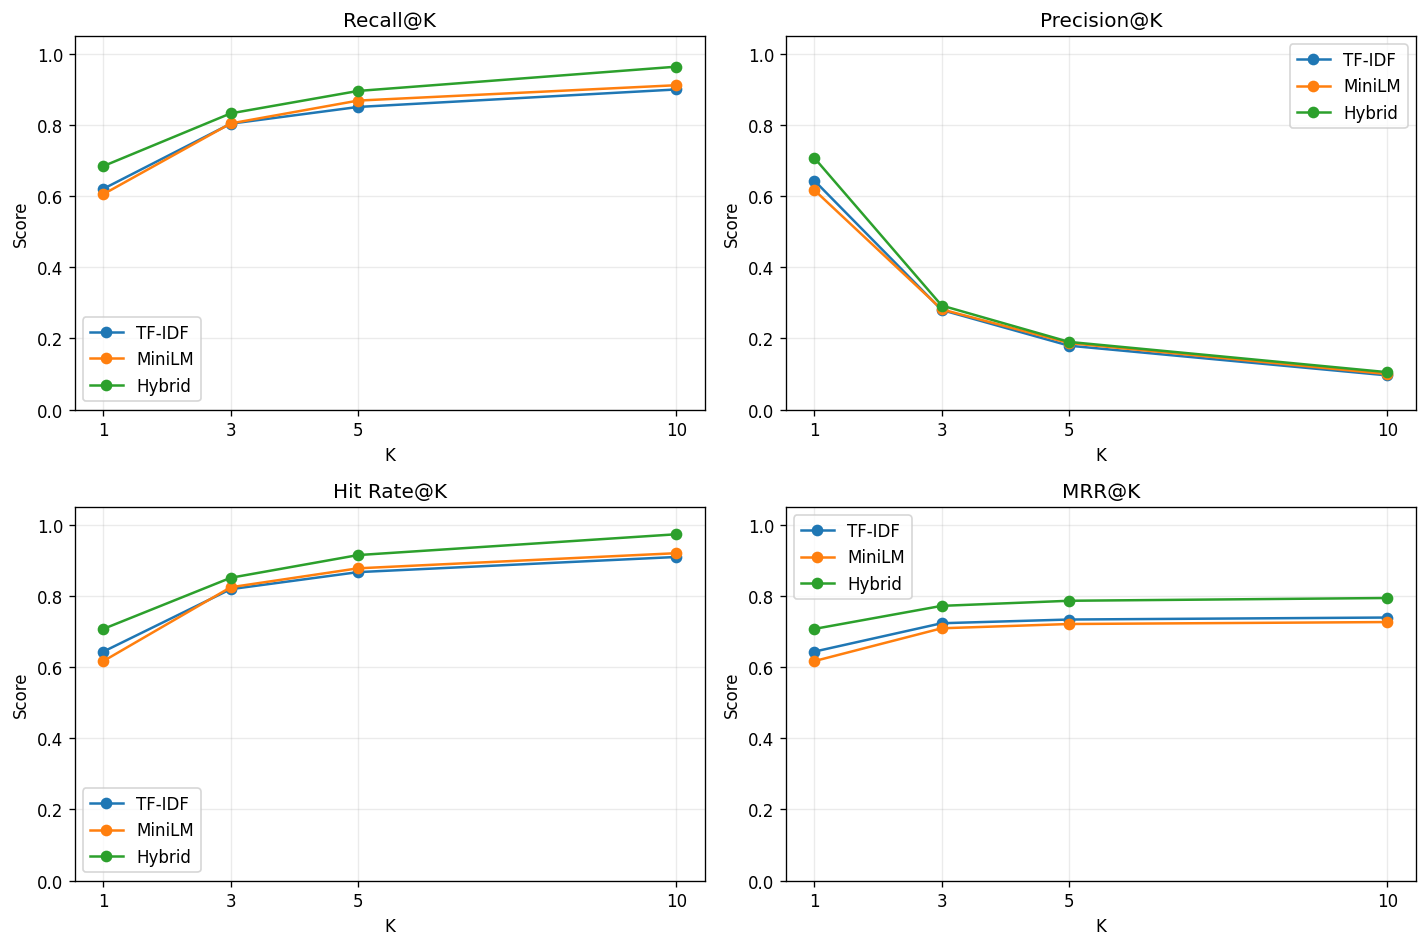

Recall@3 comparison:


,method,recall,precision,hit_rate
1,TF-IDF,0.8036,0.2801,0.8191
5,MiniLM,0.8043,0.2819,0.8245
9,Hybrid,0.8326,0.2926,0.8511


Recall@10 and MRR@10 comparison:


,method,recall,hit_rate,mrr
3,TF-IDF,0.8998,0.9096,0.7394
7,MiniLM,0.9117,0.9202,0.7267
11,Hybrid,0.9638,0.9734,0.7943


In [3]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 8)
)

metrics = [
    ("recall", "Recall@K"),
    ("precision", "Precision@K"),
    ("hit_rate", "Hit Rate@K"),
    ("mrr", "MRR@K"),
]

for ax, (column, title) in zip(
    axes.flat,
    metrics
):
    for method in retrieval_df["method"].unique():

        subset = retrieval_df[
            retrieval_df["method"] == method
        ].sort_values("k")

        ax.plot(
            subset["k"],
            subset[column],
            marker="o",
            label=method
        )

    ax.set_title(title)
    ax.set_xlabel("K")
    ax.set_ylabel("Score")
    ax.set_xticks([1, 3, 5, 10])
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.25)
    ax.legend()

save_show(
    fig,
    "04_06_retrieval_ablation.png"
)

print("Recall@3 comparison:")
display(
    retrieval_df.loc[
        retrieval_df["k"] == 3,
        ["method", "recall", "precision", "hit_rate"]
    ]
)

print("Recall@10 and MRR@10 comparison:")
display(
    retrieval_df.loc[
        retrieval_df["k"] == 10,
        ["method", "recall", "hit_rate", "mrr"]
    ]
)

### Interpretation

Hybrid retrieval outperformed both standalone retrieval methods
across all evaluated cutoffs and metrics in this development set.

Increasing K improves evidence coverage but also increases the
number of candidate documents requiring downstream verification.

Unannotated documents are not necessarily irrelevant because
benchmark evidence annotations may be incomplete.

## 2. Sentence-Level Evidence Selection

To isolate rationale selection from document retrieval errors,
the correct annotated documents are supplied directly.

The experiment contains 209 claim-document pairs from 188
claims, with 338 annotated rationale sets.

MiniLM selection is compared with a positional baseline that
selects the first three nonempty sentences.

The semantic selector retains up to three sentences using a
cosine similarity threshold of 0.40. If no sentence meets the
threshold, it selects the highest-scoring sentence.

Sentence precision, recall and F1 use the union of annotated
sentence indices per claim-document pair.

Complete rationale coverage measures whether at least one entire
annotated evidence set is contained in the predicted sentences.

,method,num_pairs,macro_precision,macro_recall,macro_f1,micro_precision,micro_recall,micro_f1,sentence_hit_rate,exact_match_rate,complete_rationale_rate,mean_selected_sentences,mean_gold_sentences,true_positives,false_positives,false_negatives
0,First-3 baseline,209,0.0957,0.1876,0.1192,0.0957,0.1639,0.1208,0.2632,0.0000,0.2201,3.0000,1.7512,60,567,306
1,MiniLM selector,209,0.3756,0.6452,0.4421,0.3618,0.5792,0.4454,0.8086,0.0239,0.7703,2.8038,1.7512,212,374,154


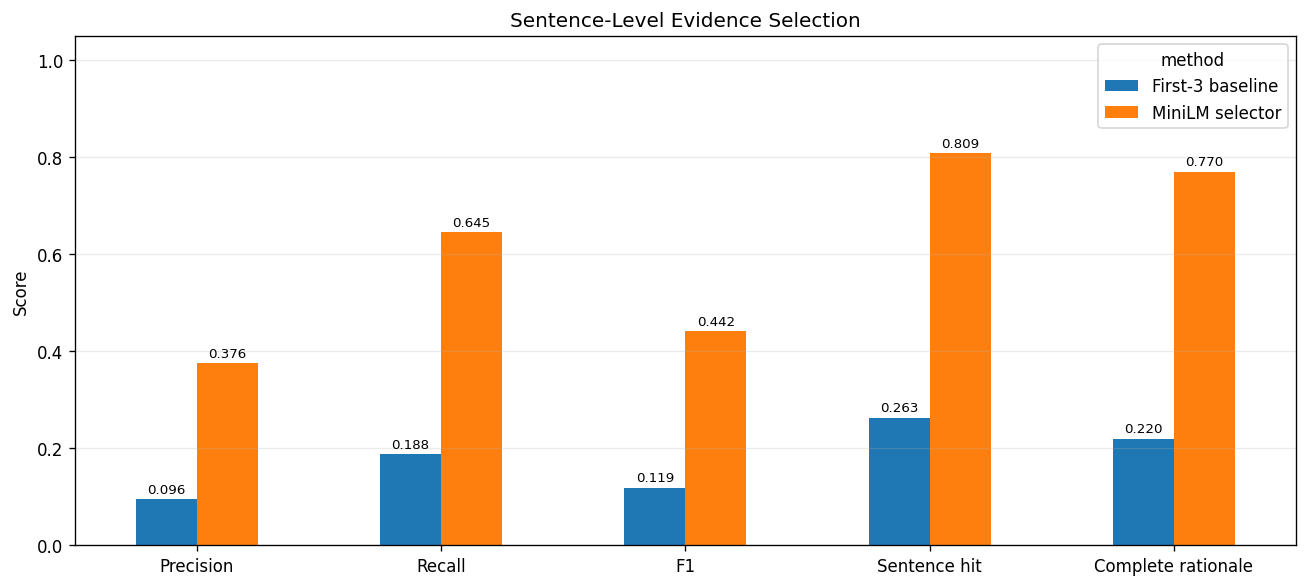

Fallback rate: 0.0048


In [4]:
display(rationale_df)

columns = [
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "sentence_hit_rate",
    "complete_rationale_rate",
]

labels = [
    "Precision",
    "Recall",
    "F1",
    "Sentence hit",
    "Complete rationale",
]

plot_df = rationale_df.set_index("method")[columns].T

plot_df.index = labels

ax = plot_df.plot(
    kind="bar",
    figsize=(11, 5),
    rot=0
)

ax.set_title("Sentence-Level Evidence Selection")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", alpha=0.25)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        fontsize=8,
        padding=2
    )

save_show(
    ax.figure,
    "04_07_rationale_selection_comparison.png"
)

print(
    "Fallback rate:",
    summary["rationale_selection"]["fallback_rate"]
)

### Interpretation

Semantic evidence selection substantially outperformed the
positional baseline in precision, recall, F1 and rationale coverage.

However, sentence precision remains limited and exact matching is
rare. Additional selected sentences may introduce irrelevant
information into the downstream classifier.

This is an oracle-document experiment, not an end-to-end measure
of evidence extraction.

## 3. Oracle Stance Classification

Two pretrained NLI models are evaluated on 338 human-annotated
claim-rationale pairs:

- Tier 1: cross-encoder/nli-deberta-v3-xsmall.
- Tier 2: cross-encoder/nli-deberta-v3-base.

The evidence is provided as the premise and the scientific claim
as the hypothesis.

Entailment maps to SUPPORT, contradiction maps to CONTRADICT,
and neutral maps to NOT_ENOUGH_INFO (NEI).

Only SUPPORT and CONTRADICT are represented in the gold labels
of this oracle experiment. NEI predictions are counted as errors.

Macro-F1 averages the SUPPORT and CONTRADICT class F1 scores.
This is not a complete three-class evaluation.

In [5]:
routing_columns = [
    "mode",
    "threshold",
    "accuracy",
    "macro_f1_support_contradict",
    "large_model_usage_rate",
    "nei_abstention_rate",
    "decisive_coverage",
    "decisive_accuracy",
    "avg_latency_ms",
]

display(routing_df[routing_columns])

routing = summary["stance_and_routing"]

majority = routing["majority_baseline"]

print("Majority-class baseline")
display(pd.DataFrame([majority]))

selected = routing_df.loc[
    np.isclose(routing_df["threshold"], 0.95)
].iloc[0]

large = routing_df.loc[
    routing_df["mode"] == "large_only"
].iloc[0]

small = routing_df.loc[
    routing_df["mode"] == "base_only"
].iloc[0]

saving = 100 * (
    1 - selected["avg_latency_ms"]
    / large["avg_latency_ms"]
)

print(
    f"Selected routing accuracy: "
    f"{selected['accuracy']:.2%}"
)

print(
    f"Selected routing macro-F1: "
    f"{selected['macro_f1_support_contradict']:.4f}"
)

print(
    f"Standalone larger-model latency: "
    f"{large['avg_latency_ms']:.2f} ms"
)

print(
    f"Selected routing latency: "
    f"{selected['avg_latency_ms']:.2f} ms"
)

print(
    f"Estimated latency reduction: "
    f"{saving:.2f}%"
)

print(
    f"Decisive prediction accuracy: "
    f"{selected['decisive_accuracy']:.2%}"
)

print(
    f"Decisive prediction coverage: "
    f"{selected['decisive_coverage']:.2%}"
)

,mode,threshold,accuracy,macro_f1_support_contradict,large_model_usage_rate,nei_abstention_rate,decisive_coverage,decisive_accuracy,avg_latency_ms
0,base_only,0.00,0.4112,0.5712,0.0000,0.5178,0.4822,0.8528,99.34
1,two_tier_0.40,0.40,0.4112,0.5712,0.0000,0.5178,0.4822,0.8528,99.34
2,two_tier_0.50,0.50,0.4112,0.5712,0.0059,0.5178,0.4822,0.8528,100.87
3,two_tier_0.60,0.60,0.4053,0.5698,0.0651,0.5296,0.4704,0.8616,116.93
4,two_tier_0.70,0.70,0.4083,0.5717,0.1272,0.5266,0.4734,0.8625,133.11
5,two_tier_0.80,0.80,0.4231,0.5883,0.2012,0.5178,0.4822,0.8773,152.26
6,two_tier_0.90,0.90,0.4320,0.5983,0.3284,0.5118,0.4882,0.8848,188.68
7,two_tier_0.95,0.95,0.4467,0.6106,0.4586,0.4941,0.5059,0.8830,222.93
8,large_only,1.01,0.4556,0.6250,1.0000,0.4970,0.5030,0.9059,266.24


Majority-class baseline


,label,accuracy,macro_f1_support_contradict
0,SUPPORT,0.6391,0.3899


Selected routing accuracy: 44.67%
Selected routing macro-F1: 0.6106
Standalone larger-model latency: 266.24 ms
Selected routing latency: 222.93 ms
Estimated latency reduction: 16.27%
Decisive prediction accuracy: 88.30%
Decisive prediction coverage: 50.59%


### Latency methodology

For standalone model configurations, only the measured latency
of that model is used.

For routed inference, the smaller-model latency is added to the
larger-model latency only when escalation occurs.

The latency estimates are derived from saved per-pair classifier
timings. They exclude retrieval, evidence selection, initial
model loading and web application overhead.

Both models are loaded during initialization. Reduced inference
latency does not establish reduced model memory usage.

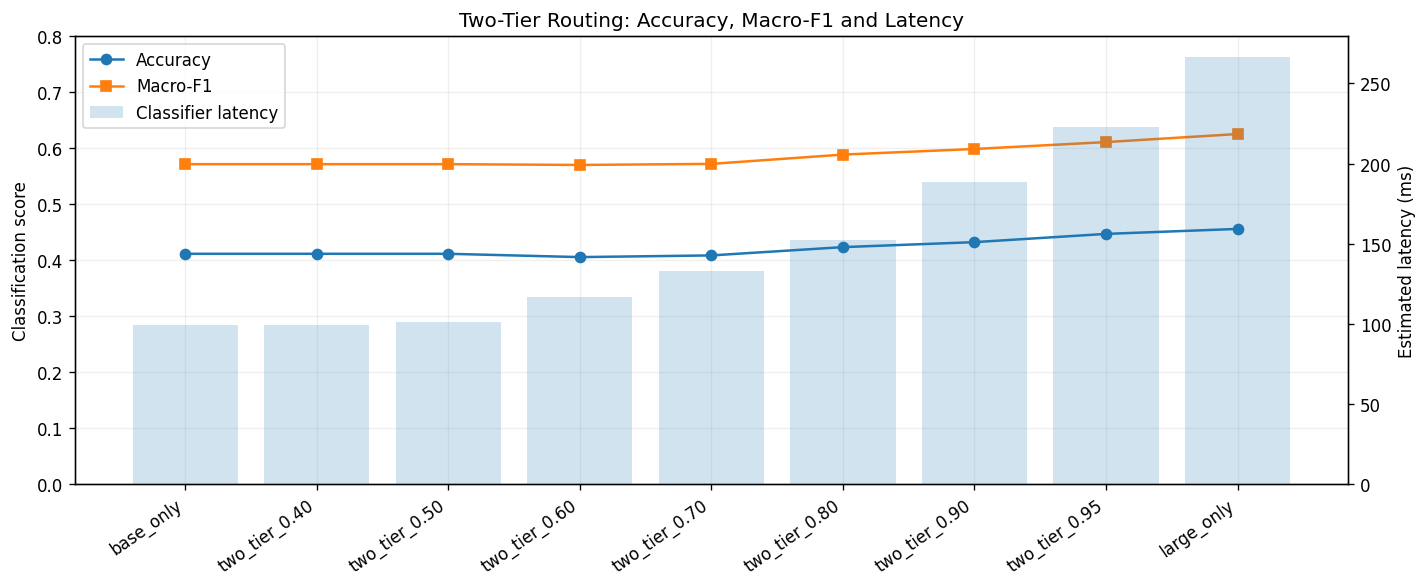

In [6]:
fig, ax = plt.subplots(figsize=(12, 5))

x = np.arange(len(routing_df))

ax.plot(
    x,
    routing_df["accuracy"],
    marker="o",
    label="Accuracy"
)

ax.plot(
    x,
    routing_df["macro_f1_support_contradict"],
    marker="s",
    label="Macro-F1"
)

ax.set_ylabel("Classification score")
ax.set_ylim(0, 0.8)

ax.set_xticks(x)

ax.set_xticklabels(
    routing_df["mode"],
    rotation=35,
    ha="right"
)

ax2 = ax.twinx()

bars = ax2.bar(
    x,
    routing_df["avg_latency_ms"],
    alpha=0.20,
    label="Classifier latency"
)

ax2.set_ylabel("Estimated latency (ms)")

handles1, labels1 = ax.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

ax.legend(
    handles1 + handles2,
    labels1 + labels2,
    loc="upper left"
)

ax.set_title(
    "Two-Tier Routing: Accuracy, Macro-F1 and Latency"
)

ax.grid(alpha=0.20)

save_show(
    fig,
    "04_02_routing_accuracy_latency_tradeoff.png"
)

### Interpretation

The routing threshold of 0.95 was selected using oracle
development-set classification experiments.

It approaches the standalone larger model's accuracy while
reducing estimated classifier latency.

Nevertheless, both pretrained models have lower overall
accuracy than the majority-class baseline. Their higher
SUPPORT/CONTRADICT Macro-F1 indicates a greater ability to
distinguish the two annotated classes.

Threshold selection is not formal probability calibration.

## 4. Confusion Matrices and Error Analysis

The following analysis distinguishes incorrect decisive
predictions from NEI predictions.

Conditional accuracy is measured only among decisive predictions.
It must be interpreted alongside overall accuracy and decisive
coverage.

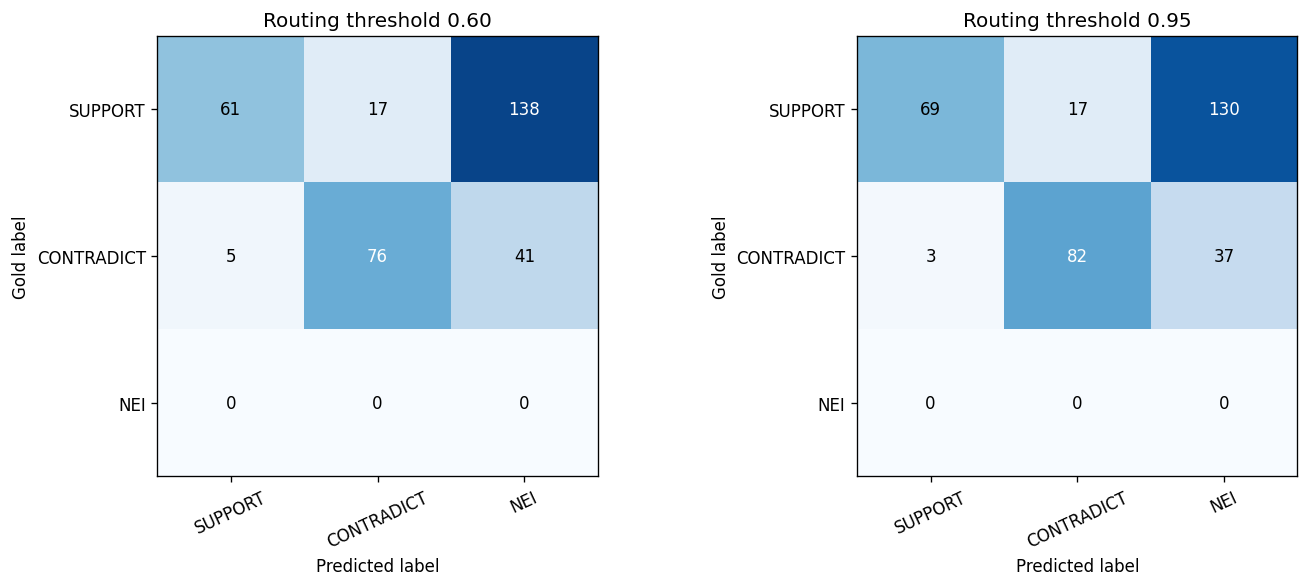

,precision,recall,f1-score,support
SUPPORT,0.958333,0.319444,0.479167,216.000000
CONTRADICT,0.828283,0.672131,0.742081,122.000000
NOT_ENOUGH_INFO,0.000000,0.000000,0.000000,0.000000
accuracy,0.446746,0.446746,0.446746,0.446746
macro avg,0.595539,0.330525,0.407083,338.000000
weighted avg,0.911392,0.446746,0.574065,338.000000


In [7]:
labels = [
    "SUPPORT",
    "CONTRADICT",
    "NOT_ENOUGH_INFO"
]

gold = stance_df["gold_label"].to_numpy()

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

for ax, threshold in zip(
    axes,
    [0.60, 0.95]
):

    preds = np.where(
        stance_df["base_conf"] < threshold,
        stance_df["large_pred"],
        stance_df["base_pred"]
    )

    cm = confusion_matrix(
        gold,
        preds,
        labels=labels
    )

    ax.imshow(
        cm,
        cmap="Blues",
        vmin=0,
        vmax=150
    )

    for i in range(3):
        for j in range(3):
            ax.text(
                j,
                i,
                str(cm[i, j]),
                ha="center",
                va="center",
                color=(
                    "white"
                    if cm[i, j] > 75
                    else "black"
                )
            )

    ax.set_xticks(range(3))
    ax.set_yticks(range(3))

    ax.set_xticklabels(
        ["SUPPORT", "CONTRADICT", "NEI"],
        rotation=25
    )

    ax.set_yticklabels(
        ["SUPPORT", "CONTRADICT", "NEI"]
    )

    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Gold label")
    ax.set_title(f"Routing threshold {threshold:.2f}")

save_show(
    fig,
    "04_03_stance_confusion_matrices.png"
)

display(
    pd.DataFrame(
        routing["classification_report_at_0.95"]
    ).T
)

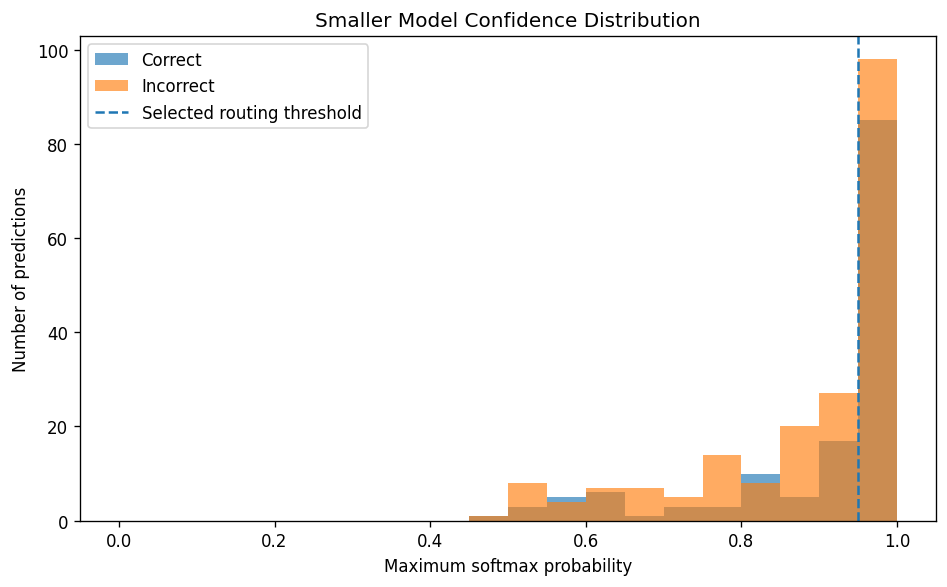

In [8]:
base_correct = (
    stance_df["base_pred"]
    == stance_df["gold_label"]
)

fig, ax = plt.subplots(figsize=(8, 5))

bins = np.linspace(0, 1, 21)

ax.hist(
    stance_df.loc[base_correct, "base_conf"],
    bins=bins,
    alpha=0.65,
    label="Correct"
)

ax.hist(
    stance_df.loc[~base_correct, "base_conf"],
    bins=bins,
    alpha=0.65,
    label="Incorrect"
)

ax.axvline(
    0.95,
    linestyle="--",
    label="Selected routing threshold"
)

ax.set_xlabel("Maximum softmax probability")
ax.set_ylabel("Number of predictions")

ax.set_title(
    "Smaller Model Confidence Distribution"
)

ax.legend()

save_show(
    fig,
    "04_04_confidence_distribution.png"
)

### Interpretation

A substantial fraction of gold SUPPORT and CONTRADICT examples
receive NEI predictions. This reduces overall accuracy.

The classifier can also produce incorrect predictions with high
confidence, limiting the effectiveness of confidence-only routing.

Softmax confidence should not be interpreted as scientific
certainty or a calibrated estimate of prediction correctness.

## 5. End-to-End Pipeline Evaluation

The full pipeline retrieves three abstracts, selects relevant
sentences and verifies each source independently.

Two routing configurations are compared on the first 60
eligible gold-annotated development claims.

The historical configuration uses threshold 0.60.
The website's default configuration uses threshold 0.95.

Claim-level aggregation selects the highest-confidence decisive
source prediction, or NEI when no decisive source exists.

Both experiments are preliminary development-set evaluations.

In [9]:
# Verify that both experiments use identical claims.

assert not old_e2e["claim_id"].duplicated().any()
assert not new_e2e["claim_id"].duplicated().any()

old_aligned = old_e2e.sort_values(
    "claim_id"
).reset_index(drop=True)

new_aligned = new_e2e.sort_values(
    "claim_id"
).reset_index(drop=True)

assert old_aligned["claim_id"].equals(
    new_aligned["claim_id"]
), "End-to-end claim IDs do not match."

assert old_aligned["claim"].equals(
    new_aligned["claim"]
), "End-to-end claim texts do not match."

assert old_aligned["gold_label"].equals(
    new_aligned["gold_label"]
), "End-to-end gold labels do not match."

assert np.allclose(
    new_aligned["routing_threshold"],
    0.95
)

print("Identical claim IDs: VERIFIED")
print("Identical claim texts: VERIFIED")
print("Identical gold labels: VERIFIED")
print("Updated routing threshold: VERIFIED")


def e2e_metrics(df, threshold):

    gold = df["gold_label"]
    pred = df["pred_label"]

    correct = gold == pred

    decisive = pred.isin(
        ["SUPPORT", "CONTRADICT"]
    )

    hit = df["gold_doc_retrieved_top3"].eq(True)

    selected_gold_rate = np.nan

    if "selected_doc_is_gold" in df.columns:

        selected_gold_rate = float(
            (
                correct
                & df["selected_doc_is_gold"].eq(True)
            ).mean()
        )

    return {
        "threshold": threshold,
        "num_claims": len(df),
        "accuracy": float(correct.mean()),
        "macro_f1": float(
            f1_score(
                gold,
                pred,
                labels=["SUPPORT", "CONTRADICT"],
                average="macro",
                zero_division=0
            )
        ),
        "gold_doc_hit_rate": float(hit.mean()),
        "joint_label_gold_hit_rate": float(
            (correct & hit).mean()
        ),
        "selected_gold_source_correct_rate": (
            selected_gold_rate
        ),
        "decisive_coverage": float(
            decisive.mean()
        ),
        "decisive_accuracy": (
            float(correct[decisive].mean())
            if decisive.any()
            else np.nan
        ),
        "correct": int(correct.sum()),
        "wrong_polarity": int(
            (decisive & ~correct).sum()
        ),
        "nei": int((~decisive).sum()),
        "potential_conflicts": int(
            df["cross_source_conflict"].sum()
        ),
    }


e2e_comparison = pd.DataFrame([
    e2e_metrics(old_aligned, 0.60),
    e2e_metrics(new_aligned, 0.95)
])

display(e2e_comparison.round(4).T)

e2e_comparison.to_csv(
    EVAL / "end_to_end_configuration_comparison.csv",
    index=False
)

old_correct = (
    old_aligned["gold_label"]
    == old_aligned["pred_label"]
)

new_correct = (
    new_aligned["gold_label"]
    == new_aligned["pred_label"]
)

print(
    "Changed predictions:",
    int(
        (
            old_aligned["pred_label"]
            != new_aligned["pred_label"]
        ).sum()
    )
)

print(
    "Incorrect to correct:",
    int((~old_correct & new_correct).sum())
)

print(
    "Correct to incorrect:",
    int((old_correct & ~new_correct).sum())
)

Identical claim IDs: VERIFIED
Identical claim texts: VERIFIED
Identical gold labels: VERIFIED
Updated routing threshold: VERIFIED


,0,1
threshold,0.6000,0.9500
num_claims,60.0000,60.0000
accuracy,0.4500,0.4333
macro_f1,0.5569,0.5296
gold_doc_hit_rate,0.8333,0.8333
joint_label_gold_hit_rate,0.3833,0.3833
selected_gold_source_correct_rate,NaN,0.3000
decisive_coverage,0.6333,0.6500
decisive_accuracy,0.7105,0.6667
correct,27.0000,26.0000


Changed predictions: 10
Incorrect to correct: 4
Correct to incorrect: 5


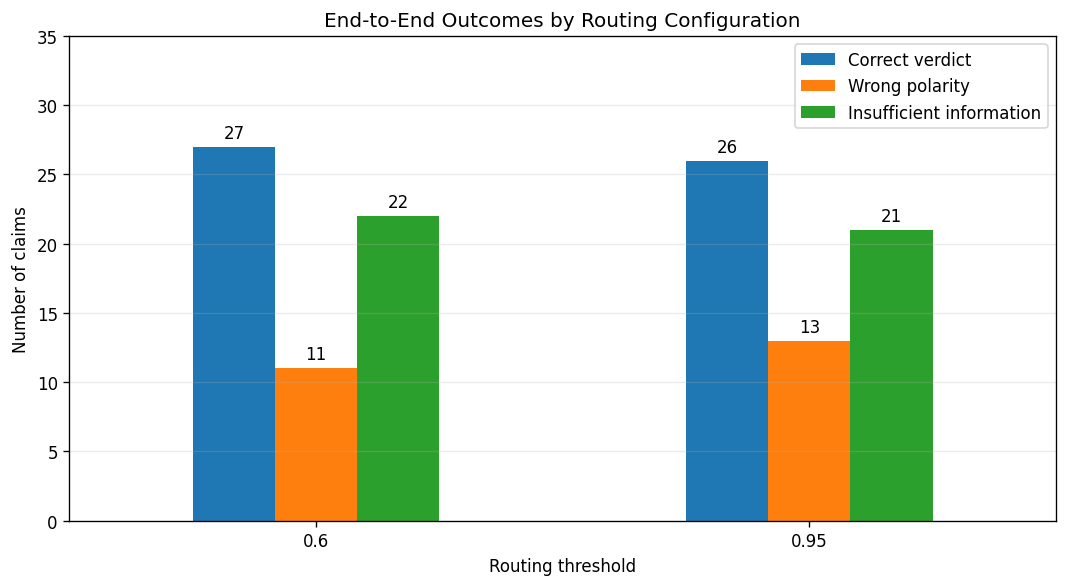

Potential cross-source conflicts at 0.95:


,claim_id,claim,gold_label,pred_label,pred_conf
15,118,Antibiotic induced alterations in the gut micr...,SUPPORT,CONTRADICT,0.9935
28,179,Birth-weight is positively associated with bre...,SUPPORT,CONTRADICT,0.9977
51,327,Deletion of αvβ8 does not result in a spontane...,SUPPORT,CONTRADICT,0.9942
54,380,Enhanced early production of inflammatory chem...,SUPPORT,CONTRADICT,0.9962


In [10]:
outcomes = e2e_comparison.set_index(
    "threshold"
)[
    ["correct", "wrong_polarity", "nei"]
]

outcomes.columns = [
    "Correct verdict",
    "Wrong polarity",
    "Insufficient information"
]

ax = outcomes.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_title(
    "End-to-End Outcomes by Routing Configuration"
)

ax.set_xlabel("Routing threshold")
ax.set_ylabel("Number of claims")
ax.set_ylim(0, 35)

for container in ax.containers:
    ax.bar_label(
        container,
        padding=3
    )

ax.grid(axis="y", alpha=0.25)

save_show(
    ax.figure,
    "04_05_end_to_end_outcomes.png"
)

print("Potential cross-source conflicts at 0.95:")

display(
    new_e2e.loc[
        new_e2e["cross_source_conflict"].eq(True),
        [
            "claim_id",
            "claim",
            "gold_label",
            "pred_label",
            "pred_conf"
        ]
    ]
)

### Interpretation

Increasing the routing threshold improved oracle classification
but did not improve the preliminary end-to-end evaluation.

This illustrates that better classifier performance on gold
evidence does not necessarily translate into better performance
when evidence is retrieved automatically.

The selected gold-source and correct-label measure is stricter
than checking whether any gold document was retrieved.

Neither measure establishes exact sentence-level grounding.

Potential cross-source conflicts represent opposing model
predictions. They do not establish that the publications
actually disagree.

The historical experiment assigned an artificial confidence
of 1.0 to aggregated NEI outcomes. Those historical confidence
values are excluded from comparative confidence analysis.
The updated implementation removes this behavior.

## 6. Controlled Claim-Edit Consistency

Five manually constructed biomedical examples were evaluated
using fixed evidence sentences.

Paraphrases are expected to preserve the predicted stance.
Negation or antonym edits are expected to reverse decisive
SUPPORT and CONTRADICT predictions.

This experiment uses the historical routing threshold of 0.60.
It is a small controlled behavior check, not an evaluation of
general end-to-end robustness.

In [11]:
display(consistency_df)

print(
    "Paraphrase consistency:",
    f"{consistency_df['paraphrase_consistent'].mean():.2%}"
)

print(
    "Negation flip rate:",
    f"{consistency_df['negation_flipped'].mean():.2%}"
)

print(
    "Number of manually constructed examples:",
    len(consistency_df)
)

,original_claim,orig_label,orig_conf,paraphrase_label,paraphrase_consistent,negated_label,negation_flipped
0,Vitamin D deficiency is associated with an inc...,SUPPORT,0.9935,SUPPORT,True,CONTRADICT,True
1,Aspirin reduces the risk of myocardial infarct...,SUPPORT,0.9934,SUPPORT,True,CONTRADICT,True
2,Elevated blood glucose levels impair wound hea...,SUPPORT,0.9883,SUPPORT,True,CONTRADICT,True
3,Regular aerobic exercise lowers resting systol...,SUPPORT,0.9930,SUPPORT,True,CONTRADICT,True
4,Antibiotics are effective against viral respir...,CONTRADICT,0.9980,CONTRADICT,True,SUPPORT,True


Paraphrase consistency: 100.00%
Negation flip rate: 100.00%
Number of manually constructed examples: 5


## 7. Qualitative Error Analysis

During manual website testing, the following claim was evaluated:

"0-dimensional biomaterials lack inductive properties."

The pipeline retrieved abstracts relating to developmental
patterning, bone strength and receptor-ligand interactions.

The extracted sentences appeared poorly aligned with the
specific biomaterials claim, yet the classifier returned
high-confidence CONTRADICT predictions.

This example was observed during a manual website demonstration
using a routing threshold of 0.85.

The example illustrates two limitations:

1. Relative retrieval scores do not guarantee relevant evidence.
2. High NLI confidence does not guarantee correct verification.

This is an illustrative qualitative observation and is not
included in the quantitative benchmark aggregates.

## 8. Final Findings and Limitations

The experiments support the following conclusions:

- Hybrid retrieval outperforms the individual lexical and
  semantic configurations on the annotated development claims.
- Semantic rationale selection substantially outperforms the
  positional sentence-selection baseline.
- Confidence-based routing offers a measurable classifier
  latency and performance trade-off on gold evidence.
- Scientific stance classification remains a major bottleneck.
- Improvements in oracle classification do not necessarily
  translate into better end-to-end verification.
- Cross-source disagreement detection is preliminary and
  requires manual scientific review.

### Limitations

- Models are not fine-tuned on the SciFact training split.
- The reported benchmark evaluations use development data.
- The oracle stance experiment lacks gold NEI examples.
- End-to-end evaluation covers a nonrandom subset of 60 claims.
- Sentence extraction is imperfect and may include noise.
- Model confidence is not formally calibrated.
- The corpus does not represent all scientific literature.
- Controlled consistency evaluation contains only five examples.

### Future work

Domain-specific NLI fine-tuning, calibrated uncertainty estimates,
evidence-aware aggregation, complete three-class evaluation,
and evaluation on independent scientific benchmarks.

### Conclusion

LitScope-Lite is a functional research prototype for
evidence-based scientific claim verification. The results
demonstrate the usefulness of hybrid retrieval and semantic
evidence selection while identifying important limitations
of zero-shot scientific stance classification.

The system is not an authoritative scientific fact-checker.